# SAM 3 polygon danger zone — contact-area overlap

This experiment is based on `tracking_clean_with_polygon_dangerzone.ipynb`. It keeps a thin contact patch along the lower envelope of each person mask and measures the actual overlap between that patch and the danger-zone mask. Cyan pixels show the contact patch and red pixels show the overlap.


In [1]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import sam3
import torch
from IPython.display import Video, display
from sam3.model_builder import build_sam3_video_predictor
from sam3.visualization_utils import load_frame

sam3_root = Path(sam3.__file__).resolve().parent.parent
utils_path = sam3_root / "examples" / "polygon_dangerzone_methods.py"
spec = importlib.util.spec_from_file_location("polygon_dangerzone_methods", utils_path)
methods = importlib.util.module_from_spec(spec)
spec.loader.exec_module(methods)

gpus_to_use = range(torch.cuda.device_count())
predictor = build_sam3_video_predictor(gpus_to_use=gpus_to_use)


c:\Users\dlatj\Desktop\study\SAM\sam3-master\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
INFO 2026-10-13 12:00:00,050 36340 sam3_video_predictor.py: 120: using the following GPU IDs: [0]
INFO 2026-10-13 12:00:00,233 36340 sam3_video_predictor.py: 136: 


	*** START loading model on all ranks ***


INFO 2026-10-13 12:00:00,233 36340 sam3_video_predictor.py: 138: loading model on rank=0 with world_size=1 -- this could take a while ...
INFO 2026-10-13 12:00:06,142 36340 sam3_video_base.py: 354: setting max_num_objects=10000 and num_obj_for_compile=16
INFO 2026-10-13 12:00:12,505 36340 sam3_video_predictor.py: 140: loading model on rank=0 with world_size=1 -- DONE locally
INFO 2026-10-13 12:00:12,505 36340 sam3_video_predictor.py: 151: 


	*** DONE loading model on all ranks ***

## Load the video and draw or reuse the polygon

The default is to reuse `danger_zone_factory_2.json`, ensuring this experiment uses the same polygon as the support-candidate experiment. Set `redraw_zone=True` only when the fixed camera or zone changes.


Loaded danger-zone config: C:\Users\dlatj\Desktop\study\SAM\sam3-master\examples\danger_zone_factory_2.json


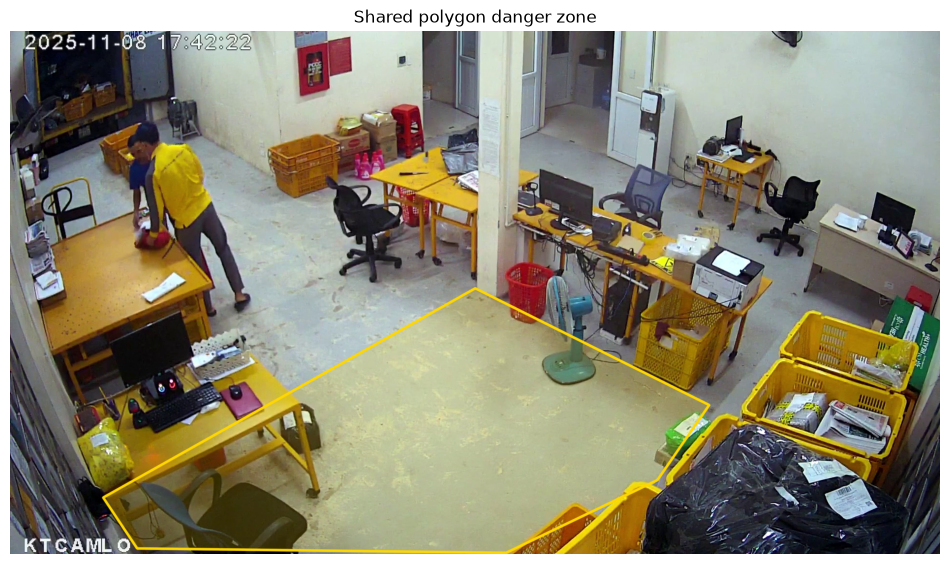

In [ ]:
video_path = sam3_root / "assets" / "videos" / "factory_2.mp4"
zone_config_path = sam3_root / "examples" / "danger_zone_factory_2.json"
output_video_path = (
    sam3_root / "examples" / "sam3_polygon_contact_area.mp4"
)
zone_frame_idx = 0
redraw_zone = True

video_frames = methods.load_video_frames(video_path)
if not video_frames:
    raise RuntimeError(f"No frames were loaded from: {video_path}")

if redraw_zone or not zone_config_path.exists():
    reference_frame = load_frame(video_frames[zone_frame_idx])
    normalized_polygon = methods.select_polygon_on_frame(reference_frame)
    methods.save_zone_config(zone_config_path, normalized_polygon, video_path)
else:
    normalized_polygon = methods.load_zone_config(zone_config_path)
    print(f"Loaded danger-zone config: {zone_config_path}")

preview = methods.preview_polygon(
    load_frame(video_frames[zone_frame_idx]), normalized_polygon
)
plt.figure(figsize=(12, 7))
plt.imshow(preview)
plt.title("Shared polygon danger zone")
plt.axis("off")
plt.show()


## Run SAM 3 person tracking


In [3]:
response = predictor.handle_request(
    request={"type": "start_session", "resource_path": str(video_path)}
)
session_id = response["session_id"]

_ = predictor.handle_request(
    request={"type": "reset_session", "session_id": session_id}
)
response = predictor.handle_request(
    request={
        "type": "add_prompt",
        "session_id": session_id,
        "frame_index": 0,
        "text": "person",
    }
)
print("Person prompt added.")


frame loading (OpenCV) [rank=0]: 100%|██████████| 237/237 [00:02<00:00, 118.46it/s]
INFO 2026-10-13 12:00:19,327 36340 sam3_base_predictor.py: 167: started new session a0072b8b-bbf5-456c-9a4c-ed26fbbd3004


Person prompt added.


## Export using contact-area overlap

`contact_band` sets the thickness of the lower-envelope patch. Entry requires both `min_overlap_pixels` and `min_overlap_ratio` to suppress single-pixel mask noise. `warning_radius` marks a near-boundary state before actual overlap.


In [4]:
outputs_per_frame = methods.propagate_in_video(predictor, session_id)

intrusion_events = methods.export_with_contact_area(
    video_frames=video_frames,
    outputs_per_frame=outputs_per_frame,
    normalized_polygon=normalized_polygon,
    output_path=output_video_path,
    fps=methods.get_video_fps(video_path),
    lower_ratio=0.35,
    contact_band=5,
    min_overlap_pixels=8,
    min_overlap_ratio=0.03,
    warning_radius=12,
    confirm_frames=3,
    exit_confirm_frames=3,
)

print(intrusion_events)
display(Video(str(output_video_path), embed=False))


propagate_in_video:   0%|          | 0/237 [00:00<?, ?it/s]

propagate_in_video: 0it [00:00, ?it/s]

INFO 2026-10-13 12:01:32,459 36340 sam3_base_predictor.py: 363: propagation ended in session a0072b8b-bbf5-456c-9a4c-ed26fbbd3004


[DANGER ZONE ENTRY] frame=146, time=4.87s, person_id=1
Saved contact-area video to: C:\Users\dlatj\Desktop\study\SAM\sam3-master\examples\sam3_polygon_contact_area.mp4
Detected 1 danger-zone entries.
[{'frame_idx': 146, 'time_seconds': 4.866666666666666, 'object_id': 1}]


## Release resources


In [5]:
_ = predictor.handle_request(
    request={"type": "close_session", "session_id": session_id}
)
predictor.shutdown()


INFO 2026-10-13 12:01:46,383 36340 sam3_base_predictor.py: 467: removed session a0072b8b-bbf5-456c-9a4c-ed26fbbd3004
